# FADAS vs FedBuff in the paper's settings

Reproduces the vision experiments of Wang et al., *FADAS: Towards Federated Adaptive Asynchronous Optimization* (ICML 2024): FADAS and its delay-adaptive version (FADASda) against FedBuff, with the **learning rates the paper uses for each method**.

**How it works**

1. The shared conditions come from `settings.yaml`. This notebook overrides only the values that define the paper's scenario and each method's learning rates (tables below), **for its own runs only**.
2. Client delays follow the paper's model: every client is put in a small, medium or large delay group (group shares drawn from Dirichlet(1)), and its delay is drawn from that group's range.
3. Every method uses the paper's client sampling: `concurrency` clients train at once, and each time an update arrives a random idle client is started.
4. Each method runs once per seed with its fixed learning rates (no tuning in this notebook), on 3 seeds.

| Setting | `settings.yaml` | Large worst-case delay (paper, run by default) | Mild delay (paper, optional) |
|---|---|---|---|
| Clients | 10 | 50 | 100 |
| Active at a time (`M_c`) | all | 25 | 20 |
| Buffer size (`M`) | 5 | 5 | 10 |
| Client delay (virtual s): small / medium / large | random | U(1,2) / U(3,5) / U(50,80) | U(1,2) / U(3,5) / U(5,8) |
| Dirichlet alpha | 0.5 | 0.1 | 0.1 |
| Client updates | 100 | 1000 | 1000 |

| Method | Local learning rate | Server rate | Source |
|---|---|---|---|
| FADAS | 0.1 | 0.001 | local rate: paper (Table 10); server rate: best on validation (0.0003 and 0.003 scored lower) |
| FADASda | 0.1 | 0.001 | both from the paper (Table 10) |
| FedBuff (paper) | 0.03 | 0.5 | local rate: paper (Table 10); server rate: 0.5 scored higher than the paper's 1.0 on validation |
| FedBuff (staleness weighted) | 0.03 | 0.5 | same as FedBuff (paper) |

> **Important:** this notebook does **not** change `settings.yaml`, the approach notebooks or `results/`. It saves only three files, in `results/paper_fadas/alpha<value>/`: `metrics.csv` (every evaluation of every run), `summary.csv` (the results table) and `accuracy_vs_updates.png`. `compare.ipynb` does not read this folder.

> **Note:** the four methods compared:
> * **FADAS**: `approaches/fadas.ipynb`, unchanged.
> * **FADASda**: the same class with `delay_adaptive=True` and `delay_threshold=8` (the best value in the paper's ablation).
> * **FedBuff (paper)**: the paper's baseline, the plain average of the buffered deltas.
> * **FedBuff (staleness weighted)**: `approaches/fedbuff.ipynb`, unchanged. It weights updates by samples / (1 + staleness).

> **Caution:** differences from the paper:
> * The dataset and model are the ones in `settings.yaml` (MNIST with an MLP, not CIFAR-10 with ResNet-18), and only 12,000 training images are shared out. Every method reaches about 90% on MNIST, so the gaps are much smaller than in the paper.
> * Each client's delay is drawn **once** and added to its upload time; the paper draws a new running time every round. Device speeds and download times still come from `settings.yaml`.
> * The paper runs 500 global rounds; 1000 updates here is 200 global steps (large delay) or 100 (mild).

## 1. Load the simulator

In [11]:
%run simulator.ipynb
import multiprocessing as mp
import tempfile
import matplotlib.pyplot as plt
plt.style.use("default")

## 2. The paper's settings

> **Tip:** to also run the paper's mild-delay setting, use `RUN = ["large_worst_case", "mild"]`. To test another heterogeneity level, change `DIRICHLET_ALPHA` to 0.3 (the paper's second level); each value is saved in its own folder.

In [12]:
SCENARIOS = {                    # the paper's two vision settings (Section 6.1); large = the slow group's delay range
    "large_worst_case": dict(num_clients=50,  concurrency=25, buffer=5,  large=(50, 80)),
    "mild":             dict(num_clients=100, concurrency=20, buffer=10, large=(5, 8)),
}
RUN = ["large_worst_case"]       # which scenarios to run
LEARNING_RATES = {               # method: (local learning rate, server rate), see the table above
    "fadas":            (0.1, 0.001),
    "fadas_da":         (0.1, 0.001),
    "fedbuff_paper":    (0.03, 0.5),
    "fedbuff_weighted": (0.03, 0.5),
}
DIRICHLET_ALPHA = 0.1
MAX_UPDATES = 1000
DELAY_THRESHOLD = 8              # tau_c for FADASda
SEEDS = [42, 43, 44]
OUT = RESULTS / "paper_fadas" / f"alpha{DIRICHLET_ALPHA}"


def paper_delays(n, large):
    """Each client joins the small, medium or large delay group (shares ~ Dirichlet(1)) and draws its delay from that range."""
    rng = np.random.default_rng(0)                 # the same clients and delays for every method and seed
    group = rng.choice(3, size=n, p=rng.dirichlet([1.0, 1.0, 1.0]))
    ranges = [(1, 2), (3, 5), large]
    return [float(rng.uniform(*ranges[g])) for g in group], np.bincount(group, minlength=3)


def overrides(scenario, method):
    """settings.yaml values replaced for one run: the scenario, plus the method's local learning rate."""
    sc = SCENARIOS[scenario]
    delays, _ = paper_delays(sc["num_clients"], sc["large"])
    return dict(num_clients=sc["num_clients"], dirichlet_alpha=DIRICHLET_ALPHA, max_updates=MAX_UPDATES,
                eval_interval=20, upload_latency=delays, lr=LEARNING_RATES[method][0])


def safe_parallel(gb_per_run=0.6, most=4):
    """Runs at the same time (one CPU thread each), limited by the free memory so the laptop never runs out."""
    try:
        free_gb = int(next(l for l in open("/proc/meminfo") if l.startswith("MemAvailable")).split()[1]) / 1e6
    except (OSError, StopIteration):
        return 1
    return max(1, min(most, int(free_gb / gb_per_run) - 1))     # keep one run's worth of memory spare


PARALLEL = safe_parallel()
for name in RUN:
    sc = SCENARIOS[name]
    groups = paper_delays(sc["num_clients"], sc["large"])[1]
    print(f"{name}: {sc['num_clients']} clients, {sc['concurrency']} active, buffer {sc['buffer']}, "
          f"delay groups small/medium/large = {groups[0]}/{groups[1]}/{groups[2]} clients")
print(f"running {PARALLEL} at a time")

large_worst_case: 50 clients, 25 active, buffer 5, delay groups small/medium/large = 18/31/1 clients
running 1 at a time


## 3. The methods

FADAS and the staleness-weighted FedBuff are loaded from their notebooks without changing them. Both FedBuff variants get the same client sampling as FADAS, so the methods differ only in how the server aggregates (and in their learning rates).

In [13]:
FADAS = load_approach("fadas")
FedBuffWeighted = load_approach("fedbuff")


class FedBuffPaper(FADAS):
    """The paper's FedBuff baseline: the plain average of the buffered deltas, scaled by server_rate."""
    name = "fedbuff_paper"
    label = "FedBuff (paper)"

    def on_update(self, server, update):
        self.buffer.append(update)
        if len(self.buffer) == self.buffer_size:
            server.set_model(apply_delta(server.model, self.buffer, [1.0] * len(self.buffer), self.server_rate), self.buffer)
            self.buffer = []


class FedBuffWeightedSampled(FedBuffWeighted):
    """approaches/fedbuff.ipynb with the paper's client sampling."""
    concurrency = None

    def start(self, server):
        self.buffer = []
        for cid in server.rng.choice(len(server.clients), self.concurrency, replace=False):
            server.train(int(cid))

    def client_free(self, server, client):
        idle = [c.id for c in server.clients if not c.busy]
        server.train(int(server.rng.choice(idle)))


METHODS = {                      # class and fixed parameters
    "fadas": (FADAS, {}),
    "fadas_da": (FADAS, dict(delay_adaptive=True, delay_threshold=DELAY_THRESHOLD)),
    "fedbuff_paper": (FedBuffPaper, {}),
    "fedbuff_weighted": (FedBuffWeightedSampled, {}),
}
LABELS = {"fadas": "FADAS", "fadas_da": "FADASda", "fedbuff_paper": "FedBuff (paper)",
          "fedbuff_weighted": "FedBuff (staleness weighted)"}

## 4. Run

Every (scenario, method, seed) is one run: 12 runs for one scenario. All runs are kept in **one** table, `metrics.csv`. Runs already in it with the same settings are **not** re-run, so if the notebook is interrupted, run it again and it continues where it stopped.

> **Note:** one scenario takes about 5 minutes when one run fits in memory at a time (`PARALLEL`, set in section 2 from the free memory; each run needs about 0.6 GB).

In [14]:
def run_one(job):
    scenario, method, seed = job
    cls, params = METHODS[method]
    sc = SCENARIOS[scenario]
    approach = cls(buffer_size=sc["buffer"], concurrency=sc["concurrency"], server_rate=LEARNING_RATES[method][1], **params)
    with tempfile.TemporaryDirectory() as tmp:     # run() writes per-run CSVs; only the combined table is kept
        m = run(approach, seeds=[seed], overrides=overrides(scenario, method), results_dir=tmp, name=method, verbose=False)
    return m.assign(scenario=scenario, method=method, rate=LEARNING_RATES[method][1])


expected_id = {(sc, m): settings_id(load_settings(**overrides(sc, m))) for sc in SCENARIOS for m in METHODS}
saved = OUT / "metrics.csv"
done = pd.read_csv(saved) if saved.exists() else None
if done is not None:          # keep only runs made with the current settings and rates
    keep = [expected_id.get((sc, m)) == sid and LEARNING_RATES.get(m, (None, None))[1] == r
            for sc, m, r, sid in zip(done.scenario, done.method, done.rate, done.settings_id)]
    done = done[keep]
have = set() if done is None else set(zip(done.scenario, done.method, done.seed))
jobs = [(sc, m, s) for sc in RUN for m in METHODS for s in SEEDS if (sc, m, s) not in have]

if jobs:
    OUT.mkdir(parents=True, exist_ok=True)
    torch.set_num_threads(1)    # before forking: otherwise every worker inherits the kernel's thread pool and the CPU is oversubscribed
    with mp.get_context("fork").Pool(PARALLEL) as pool:
        new = pool.map(run_one, jobs, chunksize=1)
    done = pd.concat(([done] if done is not None and len(done) else []) + new, ignore_index=True)
    done.to_csv(saved, index=False)
metrics = done[done.scenario.isin(RUN) & done.method.isin(list(METHODS)) & done.seed.isin(SEEDS)]
print(f"{len(jobs)} new run(s), {metrics.groupby(['scenario', 'method', 'seed']).ngroups} runs in total")

0 new run(s), 12 runs in total


## 5. Results

Test accuracy and worst-10% client accuracy (fairness), as mean and standard deviation over seeds. As in the paper, the score is the mean over the last 10% of the updates; `final_test_pct` is the last evaluation only. `max_delay` is the largest staleness any update had.

> **Note:** a lower `test_std` means the method gives similar results whatever the seed. The paper highlights this stability for FADAS, especially the delay-adaptive version.

In [15]:
def tail(m):
    return m[m.updates >= 0.9 * m.updates.max()]


per_seed = metrics.groupby(["scenario", "method", "seed"]).apply(lambda m: pd.Series({
    "test": tail(m).accuracy.mean() * 100, "worst10": tail(m).worst10_client_acc.mean() * 100,
    "final_test": m.accuracy.iloc[-1] * 100, "max_delay": m.max_staleness.max()})).reset_index()
summary = per_seed.groupby(["scenario", "method"]).agg(test_pct=("test", "mean"), test_std=("test", "std"),
                                                       worst10_pct=("worst10", "mean"), worst10_std=("worst10", "std"),
                                                       final_test_pct=("final_test", "mean"), max_delay=("max_delay", "max")).round(2)
summary.insert(0, "server_rate", [LEARNING_RATES[m][1] for _, m in summary.index])
summary.insert(0, "local_lr", [LEARNING_RATES[m][0] for _, m in summary.index])
summary = summary.reindex([(sc, m) for sc in RUN for m in METHODS]).rename(index=LABELS, level="method")
summary.to_csv(OUT / "summary.csv")
display(summary)
display(per_seed.pivot(index=["scenario", "seed"], columns="method", values="test")[list(METHODS)].rename(columns=LABELS).round(2))

local_lr  server_rate  \
scenario         method                                                
large_worst_case FADAS                             0.10        0.001   
                 FADASda                           0.10        0.001   
                 FedBuff (paper)                   0.03        0.500   
                 FedBuff (staleness weighted)      0.03        0.500   

                                               test_pct  test_std  \
scenario         method                                             
large_worst_case FADAS                            91.93      0.61   
                 FADASda                          91.65      0.37   
                 FedBuff (paper)                  91.83      1.62   
                 FedBuff (staleness weighted)     88.93      3.48   

                                               worst10_pct  worst10_std  \
scenario         method                                                   
large_worst_case FADAS                               87.86         0.42   
                 FADASda                             87.63         0.67   
                 FedBuff (paper)                     86.34         2.89   
                 FedBuff (staleness weighted)        80.15         6.48   

                                               final_test_pct  max_delay  
scenario         method                                                   
large_worst_case FADAS                                  92.15       36.0  
                 FADASda                                91.80       36.0  
                 FedBuff (paper)                        90.67       36.0  
                 FedBuff (staleness weighted)           88.18       36.0

method                 FADAS  FADASda  FedBuff (paper)  \
scenario         seed                                    
large_worst_case 42    92.60    92.07            93.45   
                 43    91.75    91.36            91.82   
                 44    91.42    91.51            90.21   

method                 FedBuff (staleness weighted)  
scenario         seed                                
large_worst_case 42                           92.92  
                 43                           87.32  
                 44                           86.54

## 6. Curves

Mean over seeds of each evaluation. One row per scenario. Left: test accuracy against client updates (the paper's x-axis). Right: worst-10% client accuracy.

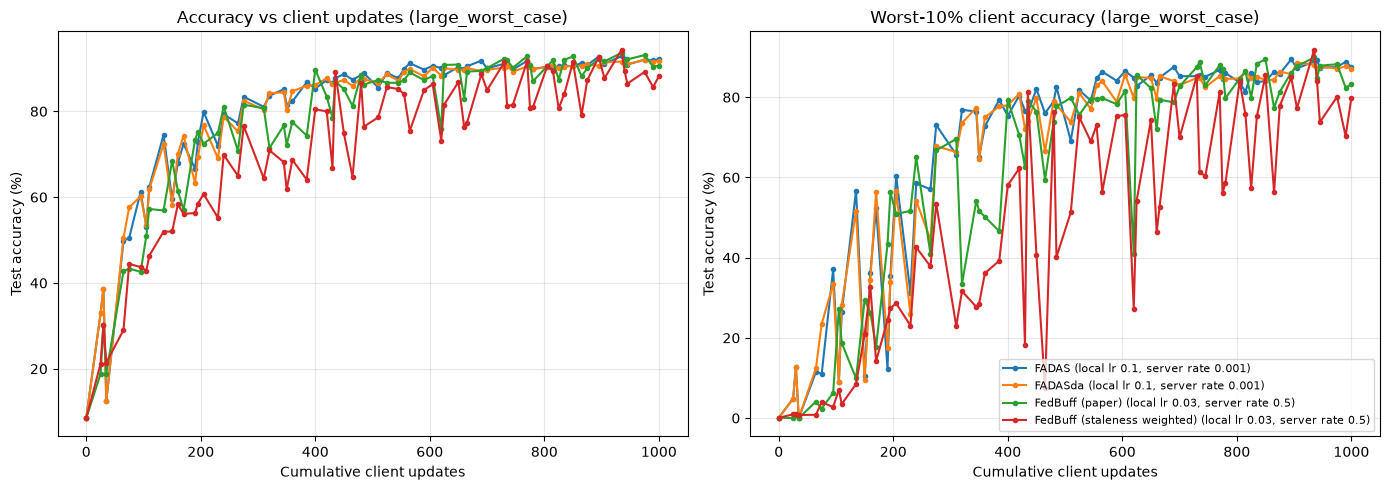

In [16]:
fig, axes = plt.subplots(len(RUN), 2, figsize=(14, 5 * len(RUN)), squeeze=False)
for row, scenario in zip(axes, RUN):
    for method in METHODS:
        g = metrics[(metrics.scenario == scenario) & (metrics.method == method)]
        c = g.groupby("version", as_index=False)[["updates", "accuracy", "worst10_client_acc"]].mean()
        label = f"{LABELS[method]} (local lr {LEARNING_RATES[method][0]}, server rate {LEARNING_RATES[method][1]})"
        row[0].plot(c.updates, c.accuracy * 100, marker="o", markersize=3, label=label)
        row[1].plot(c.updates, c.worst10_client_acc * 100, marker="o", markersize=3, label=label)
    row[0].set(xlabel="Cumulative client updates", ylabel="Test accuracy (%)", title=f"Accuracy vs client updates ({scenario})")
    row[1].set(xlabel="Cumulative client updates", ylabel="Test accuracy (%)", title=f"Worst-10% client accuracy ({scenario})")
    for ax in row:
        ax.grid(alpha=.3)
    row[1].legend(loc="best", fontsize=8)
plt.tight_layout()
fig.savefig(OUT / "accuracy_vs_updates.png", dpi=150, bbox_inches="tight")
plt.show()